In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("../data/cs-training.csv", index_col=0)

In [3]:
df.head()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [4]:
df.shape


(150000, 11)

In [5]:
df.columns

Index(['SeriousDlqin2yrs', 'RevolvingUtilizationOfUnsecuredLines', 'age',
       'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome',
       'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate',
       'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse',
       'NumberOfDependents'],
      dtype='str')

In [6]:
df["SeriousDlqin2yrs"].value_counts()


SeriousDlqin2yrs
0    139974
1     10026
Name: count, dtype: int64

In [7]:
df["SeriousDlqin2yrs"].value_counts(normalize=True)

SeriousDlqin2yrs
0    0.93316
1    0.06684
Name: proportion, dtype: float64

<Axes: xlabel='SeriousDlqin2yrs'>

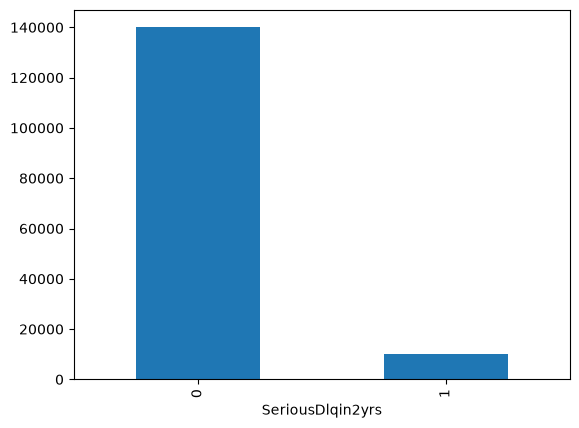

In [8]:
df["SeriousDlqin2yrs"].value_counts().plot(kind="bar")

In [9]:
df.isnull().sum()

SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64

In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeriousDlqin2yrs,150000.0,0.066840,0.249746,0.0,0.000000,0.000000,0.000000,1.0
RevolvingUtilizationOfUnsecuredLines,150000.0,6.048438,249.755371,0.0,0.029867,0.154181,0.559046,50708.0
age,150000.0,52.295207,14.771866,0.0,41.000000,52.000000,63.000000,109.0
NumberOfTime30-59DaysPastDueNotWorse,150000.0,0.421033,4.192781,0.0,0.000000,0.000000,0.000000,98.0
DebtRatio,150000.0,353.005076,2037.818523,0.0,0.175074,0.366508,0.868254,329664.0
MonthlyIncome,120269.0,6670.221237,14384.674215,0.0,3400.000000,5400.000000,8249.000000,3008750.0
NumberOfOpenCreditLinesAndLoans,150000.0,8.452760,5.145951,0.0,5.000000,8.000000,11.000000,58.0
NumberOfTimes90DaysLate,150000.0,0.265973,4.169304,0.0,0.000000,0.000000,0.000000,98.0
NumberRealEstateLoansOrLines,150000.0,1.018240,1.129771,0.0,0.000000,1.000000,2.000000,54.0
NumberOfTime60-89DaysPastDueNotWorse,150000.0,0.240387,4.155179,0.0,0.000000,0.000000,0.000000,98.0


In [11]:
df[df["age"] == 0]

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
65696,0,1.0,0,1,0.436927,6000.0,6,0,2,0,2.0


In [12]:
df = df[df["age"] > 0]
df.shape

(149999, 11)

In [13]:
df["NumberOfTimes90DaysLate"].value_counts().sort_index()


NumberOfTimes90DaysLate
0     141661
1       5243
2       1555
3        667
4        291
5        131
6         80
7         38
8         21
9         19
10         8
11         5
12         2
13         4
14         2
15         2
17         1
96         5
98       264
Name: count, dtype: int64

In [14]:
df[df["NumberOfTimes90DaysLate"] >= 90]["SeriousDlqin2yrs"].mean()

np.float64(0.5464684014869888)

In [15]:
late_cols = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
    "NumberOfTime60-89DaysPastDueNotWorse",
]

df["LateCodeFlag"] = (df[late_cols] >= 90).any(axis=1).astype(int)
df["LateCodeFlag"].value_counts()

LateCodeFlag
0    149730
1       269
Name: count, dtype: int64

In [16]:
for col in late_cols:
    df.loc[df[col] >= 90, col] = df[col].median()

df[late_cols].max()

NumberOfTime30-59DaysPastDueNotWorse    13
NumberOfTimes90DaysLate                 17
NumberOfTime60-89DaysPastDueNotWorse    11
dtype: int64

In [17]:
col = "RevolvingUtilizationOfUnsecuredLines"
print((df[col] > 1).sum())
print((df[col] > 2).sum())
print((df[col] > 10).sum())

3321
371
241


In [18]:
print(df[col].describe(percentiles=[0.9, 0.99, 0.999]))
print(df[df[col] > 10]["SeriousDlqin2yrs"].mean())

count    149999.000000
mean          6.048472
std         249.756203
min           0.000000
90%           0.981256
99%           1.092958
99.9%      1571.012000
max       50708.000000
Name: RevolvingUtilizationOfUnsecuredLines, dtype: float64
0.07053941908713693


In [19]:
df[col] = df[col].clip(upper=2)
df[col].describe()

count    149999.000000
mean          0.324485
std           0.364696
min           0.000000
25%           0.029867
50%           0.154176
75%           0.559044
max           2.000000
Name: RevolvingUtilizationOfUnsecuredLines, dtype: float64

In [20]:
col2 = "DebtRatio"
print((df[col2] > 1).sum())
print((df[col2] > 10).sum())
print((df[col2] > 100).sum())
print(df[col2].describe(percentiles=[0.9, 0.95, 0.99]))
print(df[df[col2] > 100]["SeriousDlqin2yrs"].mean())

35137
28877
24380
count    149999.000000
mean        353.007426
std        2037.825113
min           0.000000
90%        1267.000000
95%        2449.000000
99%        4979.080000
max      329664.000000
Name: DebtRatio, dtype: float64
0.05783429040196883


In [21]:
df["IncomeMissing"] = df["MonthlyIncome"].isnull().astype(int)
df["MonthlyIncome"] = df["MonthlyIncome"].fillna(df["MonthlyIncome"].median())
df["NumberOfDependents"] = df["NumberOfDependents"].fillna(df["NumberOfDependents"].median())


In [22]:
for c in ["DebtRatio", "MonthlyIncome"]:
    df[c] = df[c].clip(upper=df[c].quantile(0.99))

df.isnull().sum().sum()


np.int64(0)

In [23]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="SeriousDlqin2yrs")
y = df["SeriousDlqin2yrs"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from xgboost import XGBClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             precision_score, recall_score, f1_score)

neg, pos = (y_train == 0).sum(), (y_train == 1).sum()

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(class_weight="balanced", max_iter=1000)),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, min_samples_leaf=5,
        class_weight="balanced", n_jobs=-1, random_state=42),
    "XGBoost": XGBClassifier(
        n_estimators=300, max_depth=4, learning_rate=0.05,
        scale_pos_weight=neg / pos, random_state=42),
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    results.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_test, proba),
        "PR-AUC": average_precision_score(y_test, proba),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
    })

pd.DataFrame(results).round(3)

,Model,ROC-AUC,PR-AUC,Precision,Recall,F1
0,Logistic Regression,0.862,0.383,0.225,0.749,0.346
1,Random Forest,0.858,0.381,0.299,0.630,0.406
2,XGBoost,0.869,0.397,0.220,0.777,0.343


In [25]:
import os
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay

os.makedirs("../images", exist_ok=True)

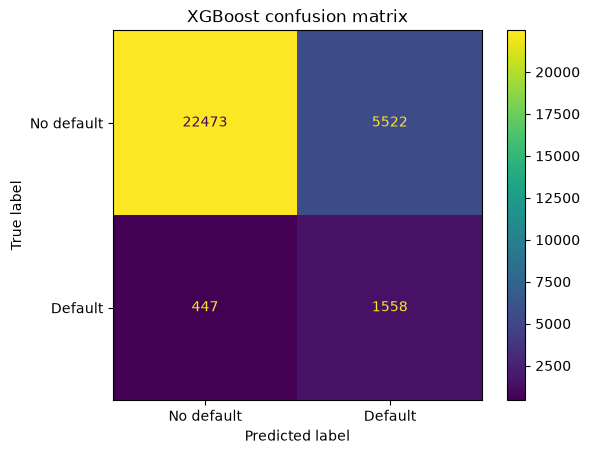

In [27]:
pred = (models["XGBoost"].predict_proba(X_test)[:, 1] >= 0.5).astype(int)
ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=["No default", "Default"])
plt.title("XGBoost confusion matrix")
plt.savefig("../images/confusion_matrix_xgboost.png", dpi=150, bbox_inches="tight")
plt.show()

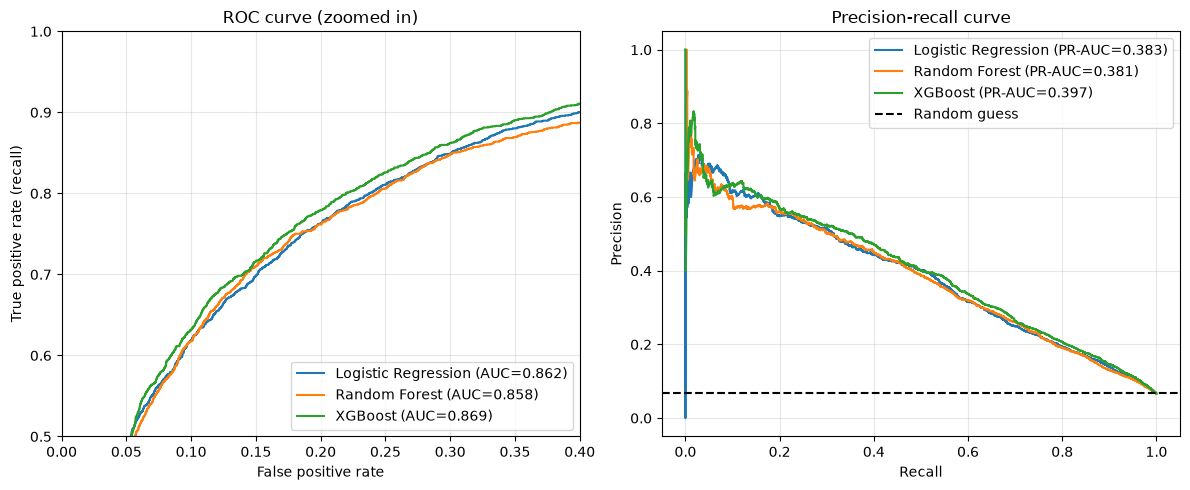

In [28]:
from sklearn.metrics import precision_recall_curve

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for name, model in models.items():
    proba = model.predict_proba(X_test)[:, 1]

    # Left: ROC curve, zoomed in
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, proba):.3f})")

    # Right: precision-recall curve
    prec, rec, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(rec, prec, label=f"{name} (PR-AUC={average_precision_score(y_test, proba):.3f})")

axes[0].set_xlim(0, 0.4)
axes[0].set_ylim(0.5, 1.0)
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate (recall)")
axes[0].set_title("ROC curve (zoomed in)")
axes[0].legend(loc="lower right")
axes[0].grid(alpha=0.3)

axes[1].axhline(y_test.mean(), color="k", linestyle="--", label="Random guess")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-recall curve")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("../images/model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()